In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
df = pd.read_csv("cp.csv")

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
    N   P   K  temperature   humidity        ph    rainfall label
0  90  42  43    20.879744  82.002744  6.502985  202.935536  rice
1  85  58  41    21.770462  80.319644  7.038096  226.655537  rice
2  60  55  44    23.004459  82.320763  7.840207  263.964248  rice
3  74  35  40    26.491096  80.158363  6.980401  242.864034  rice
4  78  42  42    20.130175  81.604873  7.628473  262.717340  rice


In [3]:
print("Shape of dataset:", df.shape)

print("\nColumn names:")
print(df.columns)

print("\nDataset information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

Shape of dataset: (2200, 8)

Column names:
Index(['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label'], dtype='str')

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 153.0 KB
None

Missing values:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64


In [4]:
df.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


In [5]:
print(df.iloc[:, -1].value_counts())

label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64


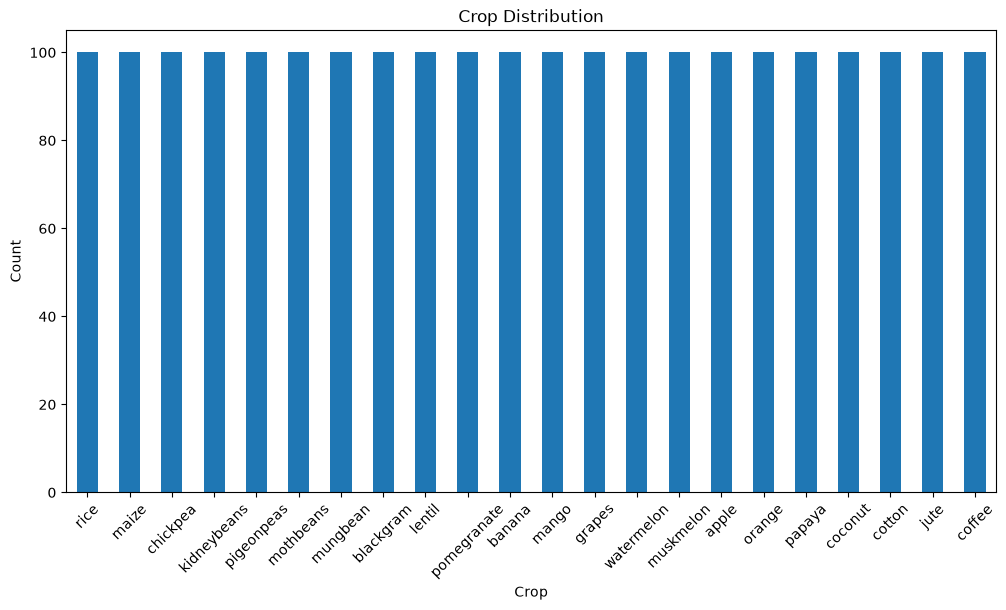

In [6]:
plt.figure(figsize=(12, 6))

df.iloc[:, -1].value_counts().plot(kind="bar")

plt.title("Crop Distribution")
plt.xlabel("Crop")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

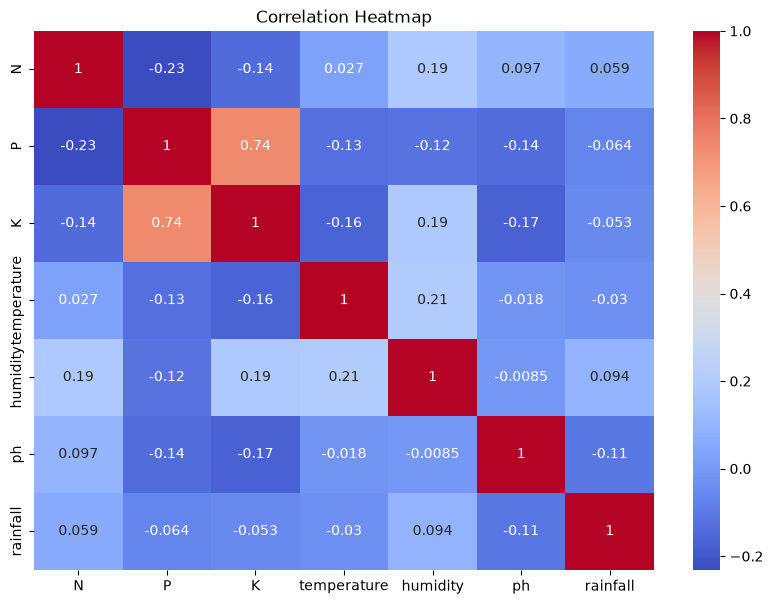

In [7]:
plt.figure(figsize=(10, 7))

sns.heatmap(df.select_dtypes(include=np.number).corr(),
            annot=True,
            cmap="coolwarm")

plt.title("Correlation Heatmap")
plt.show()

In [8]:
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

print("Input features:")
print(X.head())

print("\nTarget:")
print(y.head())

Input features:
    N   P   K  temperature   humidity        ph    rainfall
0  90  42  43    20.879744  82.002744  6.502985  202.935536
1  85  58  41    21.770462  80.319644  7.038096  226.655537
2  60  55  44    23.004459  82.320763  7.840207  263.964248
3  74  35  40    26.491096  80.158363  6.980401  242.864034
4  78  42  42    20.130175  81.604873  7.628473  262.717340

Target:
0    rice
1    rice
2    rice
3    rice
4    rice
Name: label, dtype: str


In [9]:
le = LabelEncoder()

y_encoded = le.fit_transform(y)

print("Crop classes:")
print(le.classes_)

Crop classes:
['apple' 'banana' 'blackgram' 'chickpea' 'coconut' 'coffee' 'cotton'
 'grapes' 'jute' 'kidneybeans' 'lentil' 'maize' 'mango' 'mothbeans'
 'mungbean' 'muskmelon' 'orange' 'papaya' 'pigeonpeas' 'pomegranate'
 'rice' 'watermelon']


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1760, 7)
Testing data: (440, 7)


In [11]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [12]:
y_pred = model.predict(X_test)

print("Predictions:")
print(y_pred)

Predictions:
[16  1  6 11 16  3 20  2  1 16 21 19 21 11 13  7  7 12 12  0  2  0 13  9
  0  8 13 21 20  5 12  8  1  5  8  2  7  7  2  8  4 17 12 11 10  8  6 10
  3 14 17 19 18 21 12  2 17 17  5 10 10 13  5  1 17 20 16  4  2 19  1 15
 21 10  1  4 13 14 14 12  5 21 15  9 12 19 16  6  4 17 13 14 13  6  8  7
  6  3  8 21 15 19 16 18 18  7  9 10 20 20  0 14 14  7 20 15  2 10  1 16
 16  3 11 12 11 10  1 19  4 14  6  3  8 14 13 11  0  3 20 11  6  8 19 12
 20 17  1 16 18 10 11  3  6 21 13 11 18 15  0 14  2  3 11 11  9  5 16 11
  7 19  0  4 15  7  6 10 18  3 11 13  0 15  6 21 15 21 16 21  5  9  0  3
  2  5 15  5  0  7  8 17  4  7 21 14 19 18 14 10 17 15  3  0 11  3  1 19
 19 11 16  8  6  6 11  7 14 10 18 17 14  0  1 20  3 11 20 16  2  4 20  7
  9  6 14 14  4  0 10 17 19  3  9  9 18  8 15 19  2  3 15 12  3 21  3 19
 12 13  6  8  0  9  4 17  5  9  4  4  2 10  9 14  5  6  7  5  2 13 10 21
 19  0 16 12  8  1 10 14  2 13 21 18 10  1  0  1 21  2  9 20 17  1  9  1
 15 15 16 11  1 18  8  0 10 15  4 17  

In [13]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Model Accuracy: 0.9954545454545455
Accuracy Percentage: 99.54545454545455 %


In [14]:
print(classification_report(
    y_test,
    y_pred,
    target_names=le.classes_
))

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
      papaya       1.00    

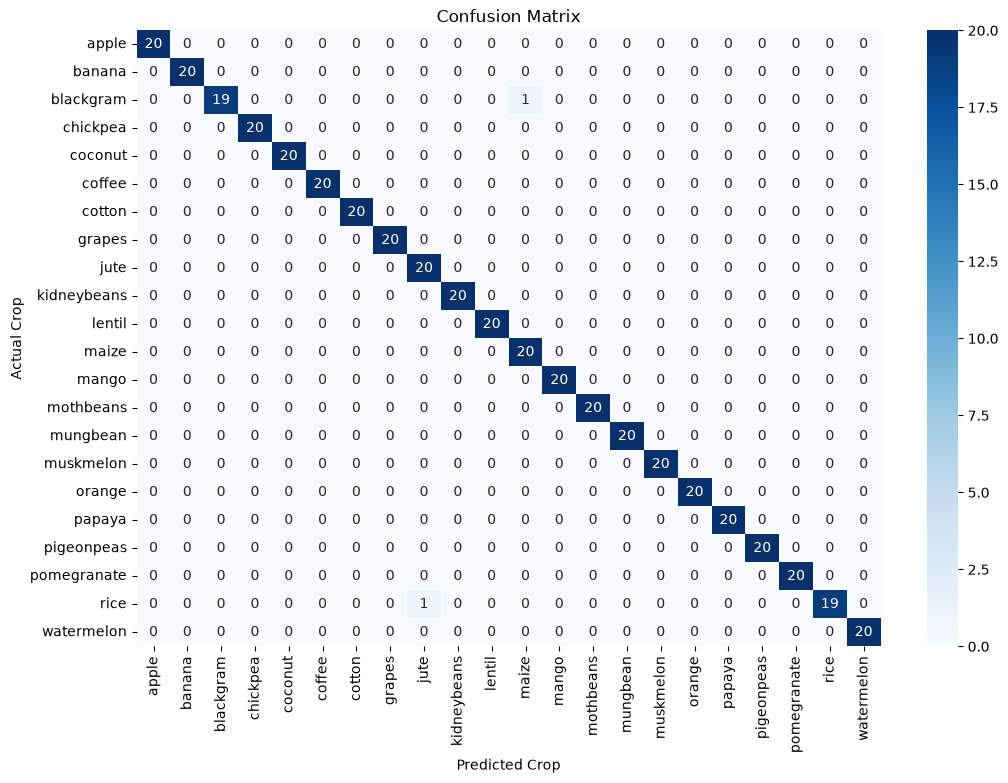

In [15]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(12, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")
plt.title("Confusion Matrix")

plt.show()

In [16]:
importance = model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

       Feature  Importance
6     rainfall    0.230184
4     humidity    0.224227
2            K    0.175393
1            P    0.150850
0            N    0.096363
3  temperature    0.072375
5           ph    0.050608


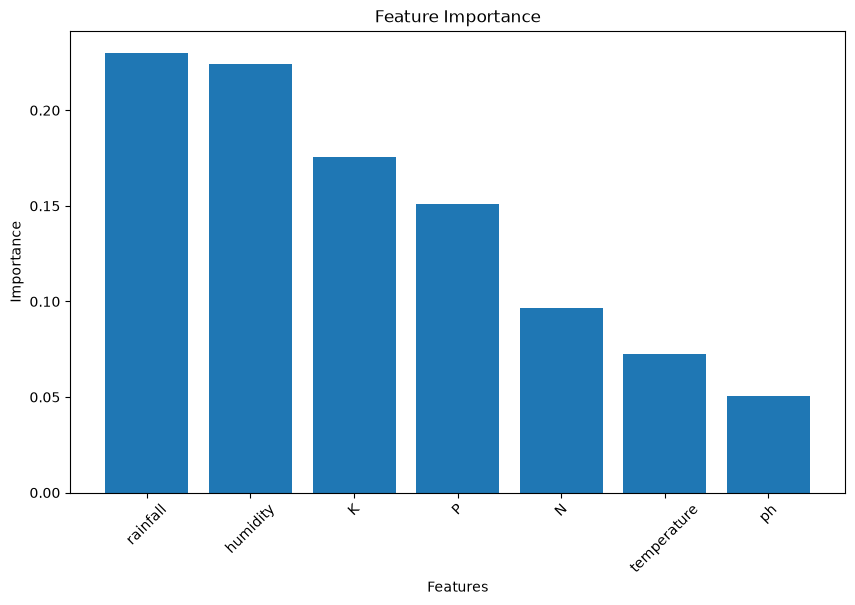

In [17]:
plt.figure(figsize=(10, 6))

plt.bar(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.title("Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")

plt.xticks(rotation=45)
plt.show()

In [20]:
print(df.columns)

Index(['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label'], dtype='str')


In [21]:
new_data = pd.DataFrame(
    [[90, 42, 43, 20.8, 82.0, 6.5, 202.9]],
    columns=['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
)

prediction = model.predict(new_data)

predicted_crop = le.inverse_transform(prediction)

print("Recommended Crop:", predicted_crop[0])

Recommended Crop: rice


In [22]:
import pickle

with open("crop_prediction_model.pkl", "wb") as file:
    pickle.dump(model, file)

with open("crop_label_encoder.pkl", "wb") as file:
    pickle.dump(le, file)

print("Model saved successfully!")

Model saved successfully!
